# Chapitre 4 - Cours 6 : Embeddings et index vectoriels

Ce notebook couvre la sous-section *Vector Embeddings* de la section
*Multidimensional and Full-Text Indexes*, nouvelle dans la 2e édition : la recherche
sémantique, les embeddings, les distances cosinus et euclidienne, et les trois familles
d'index vectoriels citées par le livre (plat, IVF, HNSW). Le livre renvoie aux articles
pour le détail des algorithmes : nous les implémentons (`ddia/storage_vectors.py`) et
mesurons le compromis rappel / coût.

**Plan.**

1. De la recherche plein texte à la recherche sémantique.
2. Mesurer la proximité : cosinus et distance euclidienne.
3. L'index plat : exact mais linéaire.
4. L'index IVF : partitionner l'espace, sonder quelques partitions.
5. L'index HNSW : un graphe de proximité à plusieurs couches.
6. Pourquoi pas un R-tree ? La malédiction de la dimension.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import storage_vectors as V
from ddia import storage as S
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## 1. De la recherche plein texte à la recherche sémantique (section *Vector Embeddings*)

La recherche plein texte trouve les documents qui contiennent **les mots** de la
requête (cours 4), avec un peu de tolérance aux fautes. La **recherche sémantique** vise
le **sens** : une page d'aide intitulée « résilier son abonnement » doit sortir pour la
requête « comment fermer mon compte », sans aucun mot commun. C'est une brique des
applications d'IA, par exemple la génération augmentée par la recherche (RAG), qui
injecte des documents trouvés dans la réponse d'un grand modèle de langage.

**L'embedding.** Un **modèle d'embedding** (souvent un réseau de neurones, parfois un
LLM) transforme un document en un **vecteur de nombres flottants**, un point dans un
espace à plusieurs centaines ou milliers de dimensions. Le modèle est entraîné pour que
des documents **proches par le sens** donnent des **points proches**. On ne cherche pas
à interpréter chaque coordonnée. Les premiers modèles travaillaient sur du texte
(Word2Vec, BERT, GPT) ; il en existe pour les images, le son, la vidéo, et des modèles
**multimodaux** qui placent texte et images dans le même espace.

Attention au faux ami : le **traitement vectorisé** du cours 5 désigne des lots de
valeurs traités par des instructions spécialisées ; ici, un **vecteur** est un point de
l'espace.

Un exemple jouet en trois dimensions (valeurs inventées pour l'illustration) :

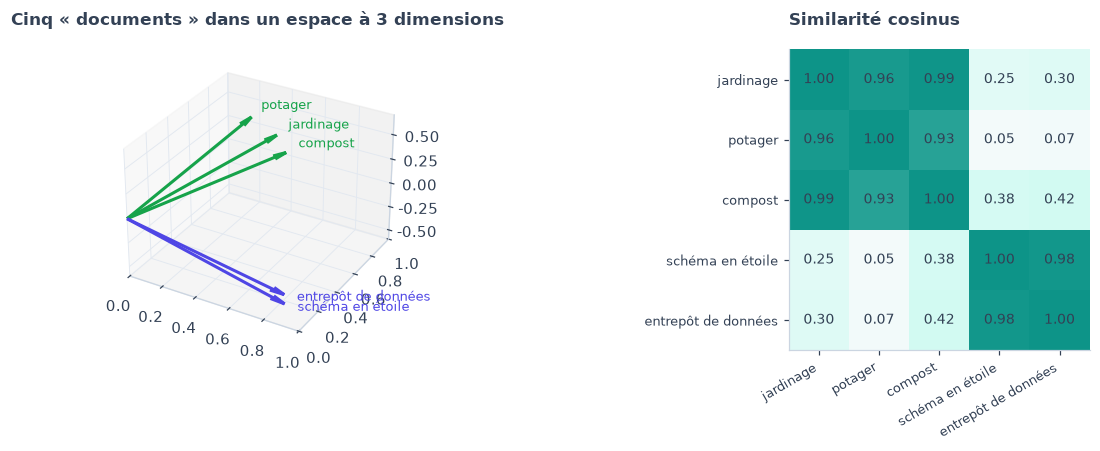

In [2]:
jouet = pd.DataFrame({
    "jardinage": [0.42, 0.80, 0.39], "potager": [0.33, 0.69, 0.62], "compost": [0.51, 0.74, 0.30],
    "schéma en étoile": [0.88, 0.07, -0.46], "entrepôt de données": [0.80, 0.21, -0.55],
}, index=["x", "y", "z"]).T
sims = pd.DataFrame({a: {b: V.cosine_similarity(jouet.loc[a], jouet.loc[b]) for b in jouet.index}
                     for a in jouet.index})
fig = plt.figure(figsize=(12, 4.2))
ax = fig.add_subplot(1, 2, 1, projection="3d")
for nom, c in zip(jouet.index, [GREEN, GREEN, GREEN, INDIGO, INDIGO]):
    v = jouet.loc[nom].to_numpy()
    ax.quiver(0, 0, 0, *v, color=c, arrow_length_ratio=0.08, lw=2)
    ax.text(*(v * 1.08), nom, fontsize=8.5, color=c)
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_zlim(-0.6, 0.7)
ax.set_title("Cinq « documents » dans un espace à 3 dimensions", fontsize=11)
ax2 = fig.add_subplot(1, 2, 2)
ax2.imshow(sims.values, cmap="ddia_div", vmin=-1, vmax=1)
for i in range(len(sims)):
    for j in range(len(sims)):
        ax2.text(j, i, f"{sims.values[i, j]:.2f}", ha="center", va="center", fontsize=9, color=SLATE)
ax2.set_xticks(range(len(sims)), sims.columns, rotation=30, ha="right", fontsize=8.5)
ax2.set_yticks(range(len(sims)), sims.index, fontsize=8.5)
ax2.grid(False)
ax2.set_title("Similarité cosinus", fontsize=11)
plt.tight_layout(); plt.show()

Les trois documents de jardinage forment un groupe (similarités supérieures à 0,9), les
deux documents sur l'analytique un autre ; entre les deux groupes, la similarité est
nettement plus faible (de 0,05 à 0,4).

**Le pipeline.** À l'indexation, chaque document passe par le modèle d'embedding et son
vecteur est rangé dans un **index vectoriel**. À la requête, le texte saisi (et
éventuellement un contexte, comme la position de l'utilisateur) passe par le **même**
modèle, et l'index renvoie les documents dont les vecteurs sont les plus proches.

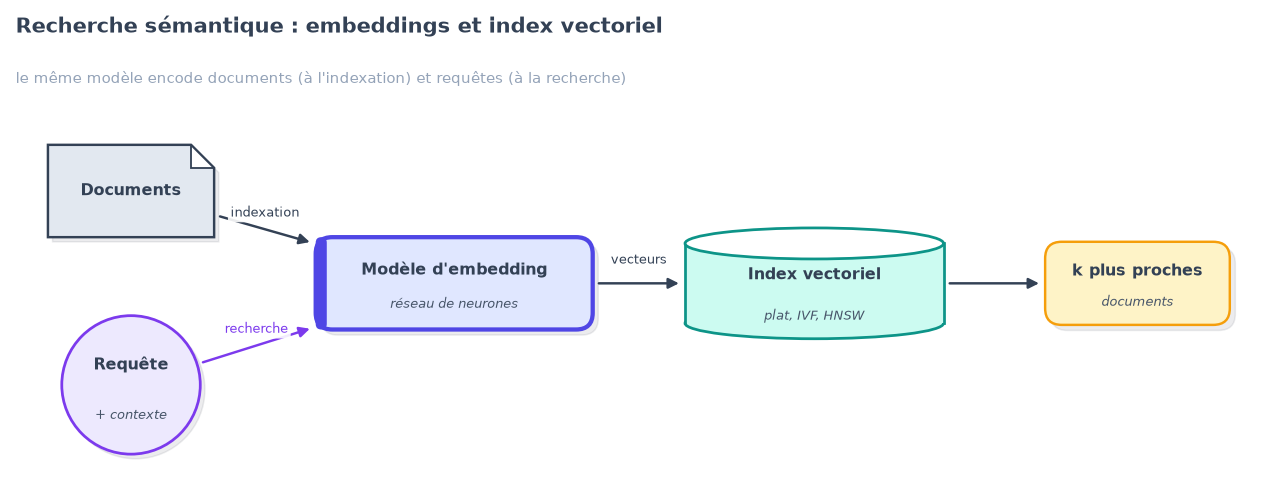

In [3]:
d = Diagram(13.5, 4.0, title="Recherche sémantique : embeddings et index vectoriel",
            subtitle="le même modèle encode documents (à l'indexation) et requêtes (à la recherche)")
d.box("docs", 1.3, 3.0, "Documents", kind="doc", color=SLATE, w=1.8, h=1.0)
d.box("q", 1.3, 0.9, "Requête", sub="+ contexte", kind="user", color=VIOLET, w=1.5)
d.box("emb", 4.8, 2.0, "Modèle d'embedding", sub="réseau de neurones", kind="model", color=INDIGO, w=3.0, h=1.0)
d.box("idx", 8.7, 2.0, "Index vectoriel", sub="plat, IVF, HNSW", kind="db", color=TEAL, w=2.8, h=1.2)
d.box("res", 12.2, 2.0, "k plus proches", sub="documents", color=AMBER, w=2.0)
d.arrow("docs", "emb", "indexation", color=SLATE)
d.arrow("q", "emb", "recherche", color=VIOLET)
d.arrow("emb", "idx", "vecteurs", label_offset=(0, 0.25))
d.arrow("idx", "res")
d.show()

> **À retenir.** Un embedding place un document dans un espace où la proximité
> géométrique reflète la proximité de sens. La recherche sémantique devient une
> recherche des **plus proches voisins** de la requête.